# Network Intrusion Detection Using Machine Learning
**Hunter Smith and John · Advanced Artificial Intelligence Final Project**

Can flow statistics help security analysts flag suspicious traffic for review? Each row describes one network flow. The target is **Benign (0)** or **Suspicious (1)** using the dataset's original labels. Compare Random Forest and linear SVM against a majority-class baseline.

**To run in Colab:** Upload this notebook, connect to a CPU runtime, and select **Runtime → Run all**. The default reads the public [CIC-IDS2017 Kaggle release](https://www.kaggle.com/datasets/dhoogla/cicids2017). The [Canadian Institute for Cybersecurity](https://www.unb.ca/cic/datasets/ids-2017.html) documents the original dataset. If the download fails, manually download and extract the Kaggle files, place the folder in Colab or mounted Drive, and set `DATA_DIR` below.

## 1. Setup and configuration

In [3]:
import sys
import subprocess
from pathlib import Path
import shutil

# Set this to an extracted dataset folder to skip the automatic download.
DATA_DIR = None
SEED = 42
MAX_ROWS_PER_FILE = 20_000  # Set to None for full files if memory allows.
OUTPUT_DIR = Path("ids_outputs")

if DATA_DIR is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
    import kagglehub
    DATA_DIR = kagglehub.dataset_download("dhoogla/cicids2017")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score,
                             confusion_matrix, f1_score, precision_score, recall_score)
from sklearn.model_selection import ParameterGrid, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

print(f"Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__}")

Using Colab cache for faster access to the 'cicids2017' dataset.
Python 3.13.18 | scikit-learn 1.6.1


## 2. Load and inspect the dataset

Prefer the Kaggle files named `*-no-metadata.parquet` when available. The loader samples up to the same cap per file to keep training manageable. This can shift the traffic mix toward categories in smaller files, so record the cap and class counts when reporting results.

In [4]:
root = Path(DATA_DIR)
parquet_paths = sorted(root.rglob("*.parquet"))
preferred_paths = [path for path in parquet_paths if "no-metadata" in path.stem.lower()]
paths = preferred_paths or parquet_paths or sorted(root.rglob("*.csv"))
if not paths:
    raise FileNotFoundError(f"No Parquet or CSV files found under {root}")

# Record how many rows were available and how many were retained from each file.
frames = []
file_summary = []
expected_columns = None
for path in paths:
    frame = pd.read_parquet(path) if path.suffix == ".parquet" else pd.read_csv(path)
    frame.columns = frame.columns.astype(str).str.strip()
    if frame.columns.has_duplicates:
        raise ValueError(f"Duplicate column names in {path.name}")
    if expected_columns is None:
        expected_columns = set(frame.columns)
    if set(frame.columns) != expected_columns:
        raise ValueError(f"Column mismatch in {path.name}. Use a single dataset variant.")
    row_count = len(frame)
    if MAX_ROWS_PER_FILE is not None and row_count > MAX_ROWS_PER_FILE:
        frame = frame.sample(n=MAX_ROWS_PER_FILE, random_state=SEED)
    frames.append(frame)
    file_summary.append({"file": path.name, "available": row_count, "sampled": len(frame)})

data = pd.concat(frames, ignore_index=True)
del frames, frame
display(pd.DataFrame(file_summary))
print(f"Sampled dataset shape: {data.shape}")

,file,available,sampled
0,Benign-Monday-no-metadata.parquet,458831,20000
1,Botnet-Friday-no-metadata.parquet,176038,20000
2,Bruteforce-Tuesday-no-metadata.parquet,389714,20000
3,DDoS-Friday-no-metadata.parquet,221264,20000
4,DoS-Wednesday-no-metadata.parquet,584991,20000
5,Infiltration-Thursday-no-metadata.parquet,207630,20000
6,Portscan-Friday-no-metadata.parquet,119522,20000
7,WebAttacks-Thursday-no-metadata.parquet,155820,20000


Sampled dataset shape: (160000, 78)


## 3. Audit, clean, and explore

Missing or blank labels: 0
Excluded from modeling: []


,missing,infinite
Protocol,0,0
Flow Duration,0,0
Total Fwd Packets,0,0
Total Backward Packets,0,0
Fwd Packets Length Total,0,0
Bwd Packets Length Total,0,0
Fwd Packet Length Max,0,0
Fwd Packet Length Min,0,0
Fwd Packet Length Mean,0,0
Fwd Packet Length Std,0,0


Conflicting-label rows removed: 4
Duplicate feature rows removed: 1253


,count,mean,std,min,25%,50%,75%,max
Protocol,158743.0,1.067187e+01,5.443142e+00,0.0,6.000000,6.0,1.700000e+01,1.700000e+01
Flow Duration,158743.0,1.585967e+07,3.451062e+07,-12.0,393.000000,61544.0,5.368844e+06,1.200000e+08
Total Fwd Packets,158743.0,1.031785e+01,7.296182e+02,1.0,2.000000,2.0,6.000000e+00,2.066870e+05
Total Backward Packets,158743.0,1.135096e+01,9.381229e+02,0.0,1.000000,2.0,5.000000e+00,2.817410e+05
Fwd Packets Length Total,158743.0,6.656708e+02,7.220655e+03,0.0,30.000000,70.0,3.270000e+02,1.645814e+06
Bwd Packets Length Total,158743.0,1.784205e+04,2.365376e+06,0.0,18.000000,175.0,1.023000e+03,6.270000e+08
Fwd Packet Length Max,158743.0,2.484616e+02,8.327989e+02,0.0,20.000000,42.0,1.940000e+02,2.336000e+04
Fwd Packet Length Min,158743.0,2.274852e+01,6.935224e+01,0.0,0.000000,6.0,4.000000e+01,1.983000e+03
Fwd Packet Length Mean,158743.0,7.006753e+01,2.157640e+02,0.0,8.666667,38.0,5.200000e+01,4.640958e+03
Fwd Packet Length Std,158743.0,8.176557e+01,3.316473e+02,0.0,0.000000,0.0,6.589838e+01,6.692645e+03


,count
Label,
Benign,139405
Suspicious,19338


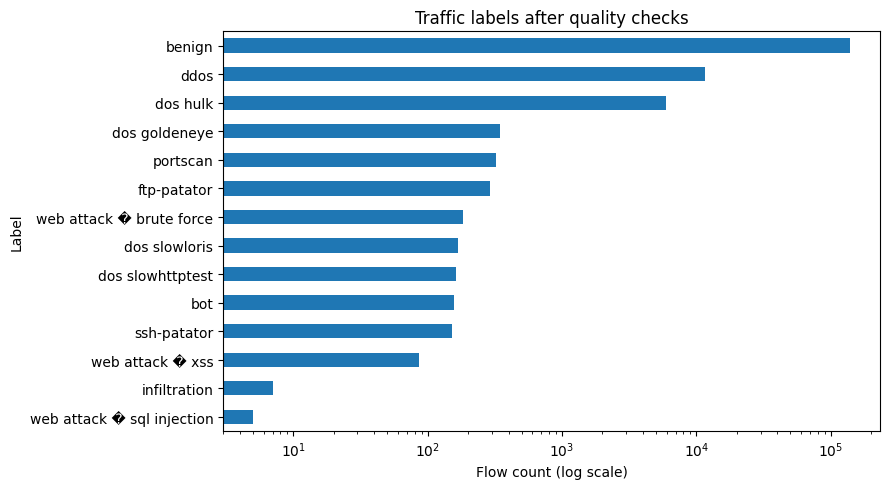

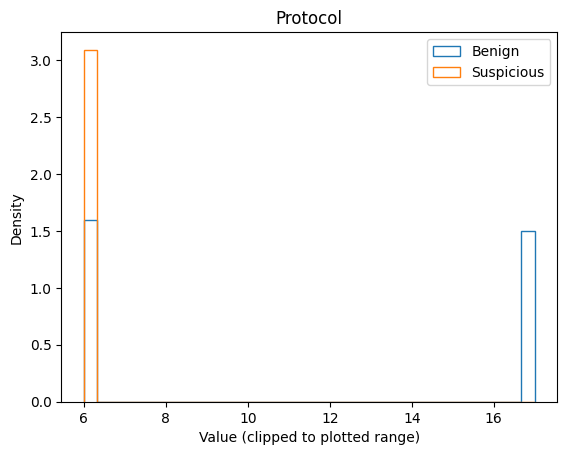

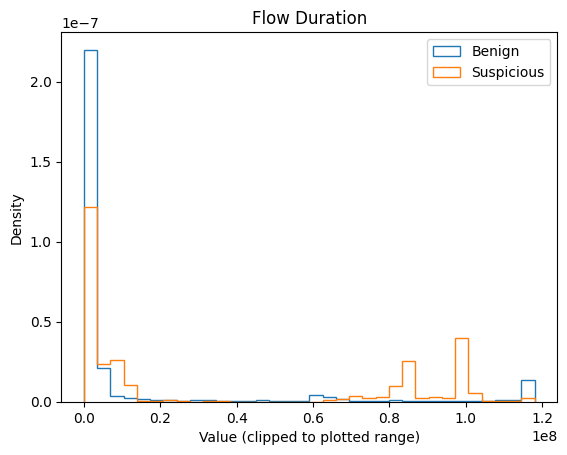

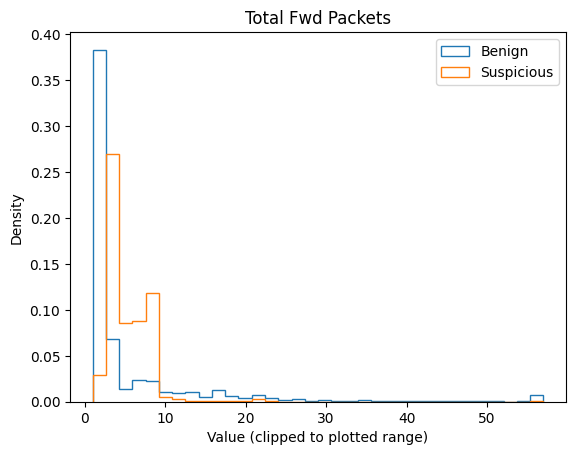

In [5]:
# Keep original labels for error analysis and derive a binary target.
label_candidates = [column for column in data if column.casefold() == "label"]
if len(label_candidates) != 1:
    raise ValueError("Expected one column named Label.")
label_column = label_candidates[0]
labels = data.pop(label_column).astype("string").str.strip().str.casefold()
has_label = labels.notna() & labels.ne("")
print("Missing or blank labels:", int((~has_label).sum()))
labels = labels.loc[has_label]
if "benign" not in labels.unique():
    raise ValueError("Expected a text label named BENIGN. Check the dataset variant.")

# Exclude identifiers and capture metadata, then keep numeric flow statistics.
metadata_names = {
    "flowid", "sourceip", "destinationip", "srcip", "dstip", "timestamp",
    "date", "time", "sourceport", "destinationport", "srcport", "dstport",
    "captureday", "capturefile", "attack", "attacktype", "class", "target",
}
metadata_columns = [
    column for column in data
    if "".join(character for character in column.lower() if character.isalnum())
    in metadata_names
]
flow_data = data.loc[has_label].drop(columns=metadata_columns)
features = flow_data.select_dtypes(include="number").astype("float32")
if features.empty:
    raise ValueError("No numeric flow features were found.")
print("Excluded from modeling:", data.columns.difference(features.columns).tolist())
quality = pd.DataFrame({
    "missing": features.isna().sum(),
    "infinite": np.isinf(features).sum(),
})
display(quality.sort_values(["missing", "infinite"], ascending=False).head(12))
features = features.replace([np.inf, -np.inf], np.nan)
target = labels.ne("benign").astype(int)

# Remove conflicting binary labels and duplicates before splitting.
# Hash matching uses only the numeric inputs the model can see.
feature_hash = pd.util.hash_pandas_object(features, index=False)
conflicting = target.groupby(feature_hash).transform("nunique").gt(1)
duplicated = feature_hash.loc[~conflicting].duplicated()
keep = duplicated.index[~duplicated]
print("Conflicting-label rows removed:", int(conflicting.sum()))
print("Duplicate feature rows removed:", int(duplicated.sum()))
features, target, labels = features.loc[keep], target.loc[keep], labels.loc[keep]

# Describe the modeling sample and visualize the original label distribution.
display(features.describe().T.head(12))
display(target.value_counts().rename(index={0: "Benign", 1: "Suspicious"}))
ax = labels.value_counts().sort_values().plot.barh(
    figsize=(9, 5), logx=True, title="Traffic labels after quality checks")
ax.set_xlabel("Flow count (log scale)")
plt.tight_layout()
plt.show()

# Show comparable distributions of up to three flow statistics.
for column in features.columns[:3]:
    values = features[column].dropna()
    if values.empty or values.nunique() < 2:
        continue
    low, high = values.quantile([0.01, 0.99])
    if low == high:
        low, high = values.min(), values.max()
    bins = np.linspace(low, high, 35)
    for value, name in [(0, "Benign"), (1, "Suspicious")]:
        group = features.loc[target.eq(value), column].dropna().clip(low, high)
        if not group.empty:
            plt.hist(group, bins=bins, density=True, histtype="step", label=name)
    plt.title(column)
    plt.xlabel("Value (clipped to plotted range)")
    plt.ylabel("Density")
    plt.legend()
    plt.show()

## 4. Split and train

Use a reproducible **60% training / 20% validation / 20% test** split, stratified by the binary label. Use validation F1 to select hyperparameters and the final model. Median imputation and constant-feature removal are fitted separately inside each pipeline. Linear SVM also scales its inputs because its margin is sensitive to feature scale. Random Forest can capture nonlinear interactions in tabular data.

In [6]:
# Keep the test set out of tuning and model selection.
development_idx, test_idx = train_test_split(
    features.index, test_size=0.20, random_state=SEED, stratify=target)
train_idx, val_idx = train_test_split(
    development_idx, test_size=0.25, random_state=SEED, stratify=target.loc[development_idx])
X_train, y_train = features.loc[train_idx], target.loc[train_idx]
X_val, y_val = features.loc[val_idx], target.loc[val_idx]
X_test, y_test = features.loc[test_idx], target.loc[test_idx]
display(pd.DataFrame({
    "train": y_train.value_counts(), "validation": y_val.value_counts(),
    "test": y_test.value_counts()
}).rename(index={0: "Benign", 1: "Suspicious"}))

# Each pipeline owns the transformations it needs at prediction time.
rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("feature_selection", VarianceThreshold()),
    ("model", RandomForestClassifier(n_estimators=75, random_state=SEED, n_jobs=2)),
])
svm = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("feature_selection", VarianceThreshold()),
    ("scale", StandardScaler()),
    ("model", LinearSVC(dual=False, max_iter=5000, random_state=SEED)),
])

experiments = {
    "Majority baseline": (DummyClassifier(strategy="most_frequent"), {}),
    "Random Forest": (rf, {"model__max_depth": [12, 24],
                          "model__class_weight": [None, "balanced"]}),
    "Linear SVM": (svm, {"model__C": [0.01, 0.1, 1.0],
                         "model__class_weight": [None, "balanced"]}),
}

# Record training and validation scores to help diagnose fit.
trials = []
best_models = {}
validation_scores = {}
for name, (estimator, grid) in experiments.items():
    best_score = -1
    for params in ParameterGrid(grid):
        model = clone(estimator).set_params(**params)
        model.fit(X_train, y_train)
        train_f1 = f1_score(y_train, model.predict(X_train), zero_division=0)
        val_f1 = f1_score(y_val, model.predict(X_val), zero_division=0)
        trials.append({"model": name, "parameters": params,
                       "train_f1": train_f1, "validation_f1": val_f1})
        if val_f1 > best_score:
            best_score = val_f1
            best_models[name] = model
    validation_scores[name] = best_score

training_results = pd.DataFrame(trials).sort_values("validation_f1", ascending=False)
display(training_results)
winner = max(("Random Forest", "Linear SVM"), key=validation_scores.get)
print("Selected on validation F1:", winner)

,train,validation,test
Label,,,
Benign,83643,27881,27881
Suspicious,11602,3868,3868


,model,parameters,train_f1,validation_f1
2,Random Forest,"{'model__class_weight': None, 'model__max_dept...",0.999871,0.989608
4,Random Forest,"{'model__class_weight': 'balanced', 'model__ma...",0.999957,0.989474
3,Random Forest,"{'model__class_weight': 'balanced', 'model__ma...",0.993932,0.988348
1,Random Forest,"{'model__class_weight': None, 'model__max_dept...",0.993367,0.987230
9,Linear SVM,"{'model__C': 1.0, 'model__class_weight': None}",0.868348,0.865260
7,Linear SVM,"{'model__C': 0.1, 'model__class_weight': None}",0.852874,0.849247
5,Linear SVM,"{'model__C': 0.01, 'model__class_weight': None}",0.823040,0.820135
10,Linear SVM,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.746971,0.745226
8,Linear SVM,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.741305,0.739173
6,Linear SVM,"{'model__C': 0.01, 'model__class_weight': 'bal...",0.736014,0.734525


Selected on validation F1: Random Forest


## 5. Compare the models on held-out flows

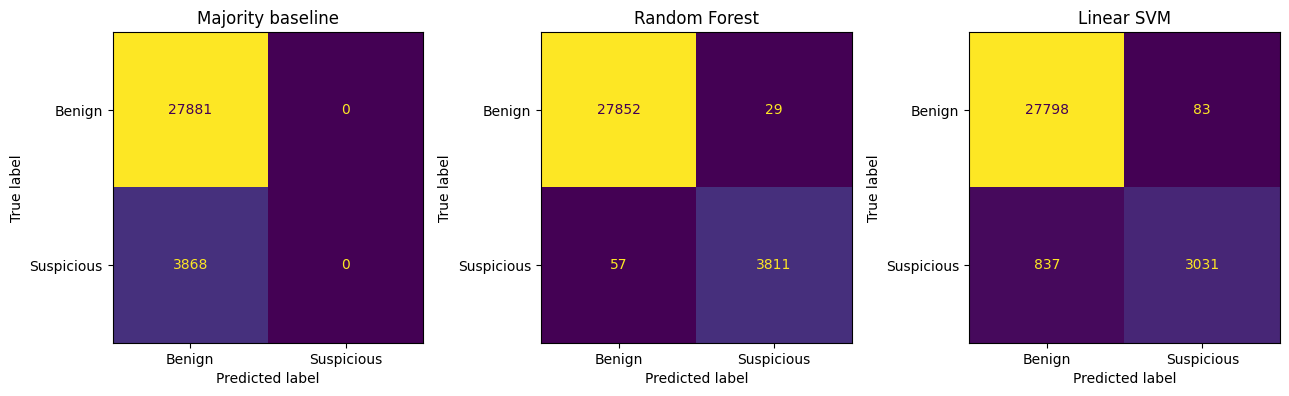

,model,precision,recall,f1,average_precision,false_positive_rate,false_alerts_per_1000_benign,missed_intrusions
0,Majority baseline,0.0000,0.0000,0.0000,0.1218,0.000,0.0000,3868
1,Random Forest,0.9924,0.9853,0.9888,0.9973,0.001,1.0401,57
2,Linear SVM,0.9733,0.7836,0.8682,0.9610,0.003,2.9769,837


,test_flows,missed_flows,recall
category,,,
bot,31,18,0.419355
dos hulk,1202,17,0.985857
ddos,2331,4,0.998284
dos goldeneye,62,3,0.951613
dos slowhttptest,37,3,0.918919
dos slowloris,29,3,0.896552
web attack � brute force,29,3,0.896552
ssh-patator,25,2,0.920000
web attack � xss,21,2,0.904762


In [7]:
# Metrics use Suspicious as the positive class.
results = []
test_predictions = {}
figure, axes = plt.subplots(1, len(best_models), figsize=(13, 4))
for ax, (name, model) in zip(axes, best_models.items()):
    prediction = model.predict(X_test)
    test_predictions[name] = prediction
    tn, fp, fn, tp = confusion_matrix(y_test, prediction, labels=[0, 1]).ravel()
    scores = (model.decision_function(X_test) if hasattr(model, "decision_function")
              else model.predict_proba(X_test)[:, list(model.classes_).index(1)])
    false_positive_rate = fp / (fp + tn)
    results.append({
        "model": name,
        "precision": precision_score(y_test, prediction, zero_division=0),
        "recall": recall_score(y_test, prediction, zero_division=0),
        "f1": f1_score(y_test, prediction, zero_division=0),
        "average_precision": average_precision_score(y_test, scores),
        "false_positive_rate": false_positive_rate,
        "false_alerts_per_1000_benign": 1000 * false_positive_rate,
        "missed_intrusions": fn,
    })
    ConfusionMatrixDisplay.from_predictions(
        y_test, prediction, labels=[0, 1], display_labels=["Benign", "Suspicious"],
        colorbar=False, ax=ax)
    ax.set_title(name)
figure.tight_layout()
plt.show()
test_results = pd.DataFrame(results)
display(test_results.round(4))

# Break down missed suspicious flows by the benchmark's original labels.
errors = pd.DataFrame({"category": labels.loc[test_idx], "actual": y_test,
                       "prediction": test_predictions[winner]})
suspicious = errors.loc[errors["actual"].eq(1)].assign(
    missed=lambda rows: rows["prediction"].eq(0))
category_results = suspicious.groupby("category")["missed"].agg(
    test_flows="size", missed_flows="sum")
category_results["recall"] = 1 - category_results["missed_flows"] / category_results["test_flows"]
display(category_results.sort_values("missed_flows", ascending=False))

### Interpret your results

- Compare the two models on recall, precision, and false alerts per 1,000 benign flows. A false positive creates an alert for an analyst to investigate. A false negative leaves a suspicious flow unflagged.
- Compare training and validation F1 for the selected settings. A large gap can suggest overfitting. Low scores on both sets can suggest underfitting or weak features.
- Use the category table to discuss missed traffic categories. Give the number of test flows when describing a category with few examples.
- The random split estimates performance on held-out flows from this benchmark. Related flows can still appear across splits, and the per-file cap changes the traffic mix. A future test on a separate capture or dataset would better measure transfer to another network. Use public flow data for the demo and avoid uploading private traffic.

## 6. Save the pipeline and demonstrate CSV predictions

In [8]:
OUTPUT_DIR.mkdir(exist_ok=True)
model_path = OUTPUT_DIR / "network_ids.joblib"
joblib.dump({
    "pipeline": best_models[winner],
    "feature_columns": X_train.columns.tolist(),
    "model_name": winner,
    "sklearn_version": sklearn.__version__,
}, model_path, compress=3)
test_results.to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
category_results.to_csv(OUTPUT_DIR / "per_category_metrics.csv")
training_results.to_csv(OUTPUT_DIR / "tuning_results.csv", index=False)

# Build an unlabeled demo CSV from held-out rows, with examples of both classes.
example_idx = y_test.groupby(y_test).head(5).index
sample_path = OUTPUT_DIR / "sample_flows.csv"
X_test.loc[example_idx].to_csv(sample_path, index=False)

def predict_csv(csv_path, artifact):
    # Select features in training order and keep missing values for imputation.
    rows = pd.read_csv(csv_path)
    required = artifact["feature_columns"]
    missing = sorted(set(required) - set(rows.columns))
    if missing:
        raise ValueError(f"Missing input columns: {missing}")
    if rows.empty:
        raise ValueError("The CSV must contain at least one flow.")
    inputs = rows.loc[:, required].apply(pd.to_numeric, errors="raise")
    inputs = inputs.astype("float32").replace([np.inf, -np.inf], np.nan)
    predictions = artifact["pipeline"].predict(inputs)
    return pd.DataFrame({
        "flow_row": np.arange(1, len(rows) + 1),
        "prediction": np.where(predictions == 1, "Suspicious", "Benign"),
    })

# Reload our own artifact to verify that the saved pipeline can run independently.
artifact = joblib.load(model_path)
predictions = predict_csv(sample_path, artifact)
predictions.to_csv(OUTPUT_DIR / "sample_predictions.csv", index=False)
display(predictions)
archive_path = shutil.make_archive("ids_outputs", "zip", root_dir=OUTPUT_DIR)
print(f"Saved {artifact['model_name']} and created {archive_path}")

,flow_row,prediction
0,1,Benign
1,2,Benign
2,3,Benign
3,4,Benign
4,5,Benign
5,6,Suspicious
6,7,Suspicious
7,8,Suspicious
8,9,Suspicious
9,10,Suspicious


Saved Random Forest and created /content/ids_outputs.zip


In [10]:
# Optional Colab actions. Set either flag to True and run this cell again.
UPLOAD_CSV = False
DOWNLOAD_OUTPUTS = True

if UPLOAD_CSV or DOWNLOAD_OUTPUTS:
    from google.colab import files

if UPLOAD_CSV:
    from io import BytesIO
    uploaded = files.upload()
    for filename, content in uploaded.items():
        print(filename)
        display(predict_csv(BytesIO(content), artifact))

if DOWNLOAD_OUTPUTS:
    files.download(archive_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Report and presentation notes

Record the exact dataset release, sample size, package versions, and selected settings. Use your generated results to explain one strength, one failure case, and one project limitation. In the presentation, show the confusion matrices and run the CSV demo using the saved pipeline. Download the output zip before ending the Colab session.

**AI-use acknowledgment.** ChatGPT helped draft the notebook, structure the comparison, and comment the code. Update this disclosure to reflect your own changes and use of AI.